<a href="https://colab.research.google.com/github/nageshappe/2048/blob/master/Yolov5_Tomato_detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
%cd /content/drive/MyDrive/

!git clone https://github.com/Gumpest/YOLOv5-Multibackbone-Compression
# %cd yolov5
%cd YOLOv5-Multibackbone-Compression

/content/drive/MyDrive
Cloning into 'YOLOv5-Multibackbone-Compression'...
remote: Enumerating objects: 432, done.
remote: Counting objects: 100% (7/7), done.
remote: Compressing objects: 100% (7/7), done.
remote: Total 432 (delta 0), reused 0 (delta 0), pack-reused 425
Receiving objects: 100% (432/432), 2.54 MiB | 8.46 MiB/s, done.
Resolving deltas: 100% (260/260), done.
/content/drive/MyDrive/YOLOv5-Multibackbone-Compression


In [2]:
# install dependencies as necessary
!pip install -qr requirements.txt  # install dependencies (ignore errors)
import torch

from IPython.display import Image, clear_output  # to display images
from utils.downloads import attempt_download  # to download models/datasets

# clear_output()
print('Setup complete. Using torch %s %s' % (torch.__version__, torch.cuda.get_device_properties(0) if torch.cuda.is_available() else 'CPU'))

Setup complete. Using torch 1.13.1+cu116 _CudaDeviceProperties(name='Tesla T4', major=7, minor=5, total_memory=15101MB, multi_processor_count=40)


In [3]:
#follow the link below to get your download code from from Roboflow
!pip install -q roboflow
from roboflow import Roboflow
rf = Roboflow(model_format="yolov5", notebook="roboflow-yolov5")


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.2/50.2 KB 3.2 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 140.6/140.6 KB 11.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.5/54.5 KB 6.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 67.8/67.8 KB 8.0 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
upload and label your dataset, and get an API KEY here: https://app.roboflow.com/?model=yolov5&ref=roboflow-yolov5


In [4]:
%cd /content/drive/MyDrive/YOLOv5-Multibackbone-Compression
!pip install roboflow

from roboflow import Roboflow
rf = Roboflow(api_key="pzQhYsonvDzrZfiTVd75")
project = rf.workspace("nagesh-pwywk").project("classification_yolov5")
dataset = project.version(1).download("yolov5")

/content/drive/MyDrive/YOLOv5-Multibackbone-Compression
Looking in indexes: https://pypi.org/simple, https://us-python.pkg.dev/colab-wheels/public/simple/
loading Roboflow workspace...
loading Roboflow project...


Extracting Dataset Version Zip to Classification_yolov5-1 in yolov5pytorch:: 100%|██████████| 2076/2076 [00:13<00:00, 159.17it/s]


In [5]:
#  this is the YAML file Roboflow wrote for us that we're loading into this notebook with our data
%cat {dataset.location}/data.yaml

names:
- ripe
- unripe
nc: 2
train: Classification_yolov5-1/train/images
val: Classification_yolov5-1/valid/images


In [7]:
# define number of classes based on YAML
import yaml
with open(dataset.location + "/data.yaml", 'r') as stream:
    num_classes = str(yaml.safe_load(stream)['nc'])

In [8]:
#this is the model configuration we will use for our tutorial 
# %cat /content/yolov5/models/yolov5s.yaml
%cat /content/drive/MyDrive/YOLOv5-Multibackbone-Compression/models/yolov5s.yaml


# YOLOv5 🚀 by Ultralytics, GPL-3.0 license

# Parameters
nc: 80  # number of classes
depth_multiple: 0.33  # model depth multiple
width_multiple: 0.50  # layer channel multiple
anchors:
  - [3,4,  4,8,  7,6]  # P3/8
  - [7,12,  15,9,  12,18]  # P4/16
  - [27,15,  23,29,  46,36]  # P5/32

# YOLOv5 v6.0 backbone
backbone:
  # [from, number, module, args]
  [[-1, 1, Conv, [64, 6, 2, 2]],  # 0-P1/2
   [-1, 1, Conv, [128, 3, 2]],  # 1-P2/4
   [-1, 3, C3, [128]],
   [-1, 1, Conv, [256, 3, 2]],  # 3-P3/8
   [-1, 6, C3, [256]],
   [-1, 1, Conv, [512, 3, 2]],  # 5-P4/16
   [-1, 9, C3, [512]],
   [-1, 1, Conv, [1024, 3, 2]],  # 7-P5/32
   [-1, 3, C3, [1024]],
   [-1, 1, SPPF, [1024, 5]],  # 9
  ]

# YOLOv5 v6.0 head
head:
  [[-1, 1, Conv, [512, 1, 1]],
   [-1, 1, nn.Upsample, [None, 2, 'nearest']],
   [[-1, 6], 1, Concat, [1]],  # cat backbone P4
   [-1, 3, C3, [512, False]],  # 13

   [-1, 1, Conv, [256, 1, 1]],
   [-1, 1, nn.Upsample, [None, 2, 'nearest']],
   [[-1, 4], 1, Concat, [1]],  # cat

In [9]:
#customize iPython writefile so we can write variables
from IPython.core.magic import register_line_cell_magic

@register_line_cell_magic
def writetemplate(line, cell):
    with open(line, 'w') as f:
        f.write(cell.format(**globals()))

In [19]:
# %%writetemplate /content/yolov5/models/custom_yolov5s.yaml
%%writetemplate /content/drive/MyDrive/YOLOv5-Multibackbone-Compression/models/custom_yolov5s.yaml
# Parameters
nc: 2 # number of classes
depth_multiple: 0.33  # model depth multiple
width_multiple: 0.50  # layer channel multiple
anchors:
  - [3,4,  4,8,  7,6]  # P3/8
  - [7,12,  15,9,  12,18]  # P4/16
  - [27,15,  23,29,  46,36]  # P5/32

# YOLOv5 v6.0 backbone
backbone:
  # [from, number, module, args]
  [[-1, 1, Conv, [64, 6, 2, 2]],  # 0-P1/2
   [-1, 1, Conv, [128, 3, 2]],  # 1-P2/4
   [-1, 3, C3, [128]],
  #  [-1,1,CBAM ,[128]],
   [-1, 1, Conv, [256, 3, 2]],  # 4-P3/8
   [-1, 6, C3, [256]],
   [-1,1,CBAM, [256]],
   [-1, 1, Conv, [512, 3, 2]],  # 7-P4/16
   [-1, 9, C3, [512]],
   [-1,1,CBAM, [512]],
   [-1, 1, Conv, [1024, 3, 2]],  # 10-P5/32
   [-1, 3, C3, [1024]],
   [-1, 1, SPPF, [1024, 5]],  # 12
  ]

# YOLOv5 v6.0 head
head:
  [[-1, 1, Conv, [512, 1, 1]],
   [-1, 1, nn.Upsample, [None, 2, 'nearest']],
   [[-1, 6], 1, Concat, [1]],  # cat backbone P4
   [-1, 3, C3, [512, False]],  # 16

   [-1, 1, Conv, [256, 1, 1]],
   [-1, 1, nn.Upsample, [None, 2, 'nearest']],
   [[-1, 4], 1, Concat, [1]],  # cat backbone P3
   [-1, 3, C3, [256, False]],  # 20 (P3/8-small)

   [-1, 1, Conv, [256, 3, 2]],
   [[-1, 14], 1, Concat, [1]],  # cat head P4
   [-1, 3, C3, [512, False]],  # 23 (P4/16-medium)

   [-1, 1, Conv, [512, 3, 2]],
   [[-1, 10], 1, Concat, [1]],  # cat head P5
   [-1, 3, C3, [1024, False]],  # 26 (P5/32-large)

   [[19,22,25], 1, Detect, [nc, anchors]],  # Detect(P3, P4, P5)
  ]

In [11]:
!pip install timm

Looking in indexes: https://pypi.org/simple, https://us-python.pkg.dev/colab-wheels/public/simple/
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 549.1/549.1 KB 14.7 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 190.3/190.3 KB 20.1 MB/s eta 0:00:00


In [29]:
# train yolov5s on custom data for 100 epochs
# time its performance
%%time

# %cd /content/yolov5/
%cd /content/drive/MyDrive/YOLOv5-Multibackbone-Compression
!python train.py --img 416 --batch 16 --epochs 100 --data {dataset.location}/data.yaml --cfg /content/drive/MyDrive/YOLOv5-Multibackbone-Compression/models/custom_yolov5s.yaml --weights '' --name yolov5s_results  --cache --adam

/content/drive/MyDrive/YOLOv5-Multibackbone-Compression
train: weights=, cfg=/content/drive/MyDrive/YOLOv5-Multibackbone-Compression/models/custom_yolov5s.yaml, data=/content/drive/MyDrive/YOLOv5-Multibackbone-Compression/Classification_yolov5-1/data.yaml, hyp=data/hyps/hyp.scratch.yaml, epochs=100, batch_size=16, imgsz=416, rect=False, resume=False, nosave=False, noval=False, noautoanchor=False, evolve=None, bucket=, cache=ram, image_weights=False, device=, multi_scale=False, single_cls=False, adam=True, sync_bn=False, workers=8, project=runs/train, name=yolov5s_results, exist_ok=False, quad=False, linear_lr=False, label_smoothing=0.0, patience=100, freeze=0, save_period=-1, local_rank=-1, nohalf=False, quantize=False, BackendType=Tensorrt, entity=None, upload_dataset=False, bbox_interval=-1, artifact_alias=latest, sparse=False, sparse_rate=0.001
fatal: ambiguous argument 'main..origin/master': unknown revision or path not in the working tree.
Use '--' to separate paths from revisions

In [ ]:
import torch
torch.cuda.empty_cache()

In [30]:
# Start tensorboard
# Launch after you have started training
# logs save in the folder "runs"
%load_ext tensorboard
%tensorboard --logdir runs

<IPython.core.display.Javascript object>

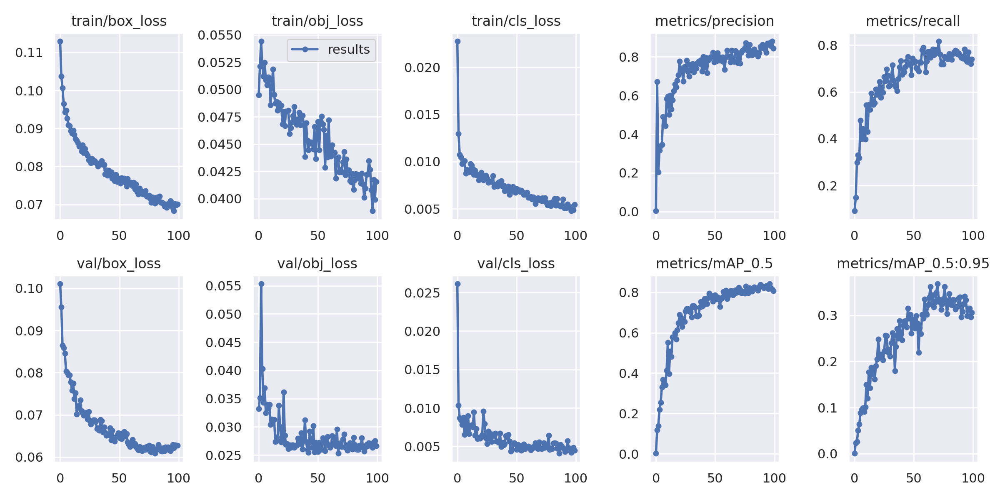

In [32]:
# we can also output some older school graphs if the tensor board isn't working for whatever reason... 
from utils.plots import plot_results  # plot results.txt as results.png

Image(filename='/content/drive/MyDrive/YOLOv5-Multibackbone-Compression/runs/train/yolov5s_results15/results.png', width=1000)  # view results.png

In [37]:
# trained weights are saved by default in our weights folder
%cd /content/drive/MyDrive/YOLOv5-Multibackbone-Compression
%ls runs/

/content/drive/MyDrive/YOLOv5-Multibackbone-Compression
detect/  train/


In [38]:
%ls runs/train/yolov5s_results/weights

In [41]:
# when we ran this, we saw .007 second inference time. That is 140 FPS on a TESLA P100!
# use the best weights!

!python detect.py --weights runs/train/yolov5s_results15/weights/best.pt --img 416 --conf 0.4 --source /content/drive/MyDrive/YOLOv5-Multibackbone-Compression/Classification_yolov5-1/test/images

detect: weights=['runs/train/yolov5s_results15/weights/best.pt'], source=/content/drive/MyDrive/YOLOv5-Multibackbone-Compression/Classification_yolov5-1/test/images, imgsz=[416, 416], conf_thres=0.4, iou_thres=0.45, max_det=1000, device=, view_img=False, save_txt=False, save_conf=False, save_crop=False, nosave=False, classes=None, agnostic_nms=False, augment=False, visualize=False, update=False, project=runs/detect, name=exp, exist_ok=False, line_thickness=3, hide_labels=False, hide_conf=False, half=False, dnn=False
YOLOv5 🚀 6d7f715 torch 1.13.1+cu116 CUDA:0 (Tesla T4, 15101.8125MB)

Fusing layers... 
/usr/local/lib/python3.8/dist-packages/torch/functional.py:504: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at ../aten/src/ATen/native/TensorShape.cpp:3190.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]
Model Summary: 235 layers, 7255331 parameters, 0 gradients, 16.2 GFLOPs
image 1/

In [ ]:
!python detect.py --weights runs/train/yolov5s_results8/weights/best.pt --img 416 --conf 0.4 --source '/content/tomagoimage2.jpg'

detect: weights=['runs/train/yolov5s_results8/weights/best.pt'], source=/content/tomagoimage2.jpg, imgsz=[416, 416], conf_thres=0.4, iou_thres=0.45, max_det=1000, device=, view_img=False, save_txt=False, save_conf=False, save_crop=False, nosave=False, classes=None, agnostic_nms=False, augment=False, visualize=False, update=False, project=runs/detect, name=exp, exist_ok=False, line_thickness=3, hide_labels=False, hide_conf=False, half=False, dnn=False
YOLOv5 🚀 6d7f715 torch 1.13.1+cu116 CUDA:0 (Tesla T4, 15101.8125MB)

Fusing layers... 
/usr/local/lib/python3.8/dist-packages/torch/functional.py:504: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at ../aten/src/ATen/native/TensorShape.cpp:3190.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]
Model Summary: 213 layers, 7015519 parameters, 0 gradients, 15.8 GFLOPs
image 1/1 /content/tomagoimage2.jpg: 416x320 4 ripes, 9 unripes, Done. (0.0

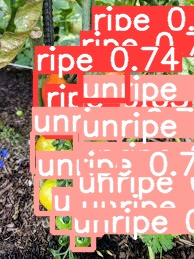

In [ ]:
# display inference on ALL test images
#this looks much better with longer training abov4

import glob
from IPython.display import Image, display

for imageName in glob.glob('/content/YOLOv5-Multibackbone-Compression/runs/detect/exp3/*.jpg'): #assuming JPG
    display(Image(filename=imageName))
    print("\n")